# Running a simulation interactively in Python

The code cells open a committed result of the Hurricane Irene event from the [observed-event ensemble](../norfolk-observed-events/), trimmed to the variables that the plots read, and plot the difference between the models. The result is stored in the repository, so the cells run without a solver.

## Run a simulation

The [quickstart](../../quickstart/) runs the Norfolk example from an interactive Python session with the following calls:

```python
from hhemt.experiments import NorfolkIreneExperiment
# hhemt_sha is the 40-hex commit you are running; `git rev-parse HEAD` prints it.
norfolk = NorfolkIreneExperiment.load(hhemt_sha="REPLACE-WITH-THE-FULL-40-HEX-HHEMT-COMMIT")
norfolk.system.compile_TRITON_SWMM()          # once per machine: clones and builds the solver
result = norfolk.analysis.run(from_scratch=False, execution_mode="auto")
```

The calls do the following:

- `NorfolkIreneExperiment.load()` downloads the Norfolk data once and returns an experiment. The `.analysis` attribute of the experiment is the orchestrator, and the `.system` attribute holds the DEM and the compilation state.
- `compile_TRITON_SWMM()` clones and builds the coupled solver on the first call on a machine and skips the build afterwards. The call precedes the first `run()` on every machine, and [Compile the solver](../../how-to/compiling-the-solver/) covers the cluster form.
- `analysis.run()` runs the simulations. The argument `from_scratch=False` resumes completed work, and `execution_mode="auto"` reads `multi_sim_run_method` from the analysis config, so the Norfolk example runs on the local machine.

A smoke test can precede the analysis and a report can follow. `norfolk.analysis.test()` is an optional smoke test that runs a least-demanding subset of the analysis under `{analysis_dir}/_test/`, so a missing solver or input shows early. `norfolk.analysis.render_report()` assembles the report from the completed outputs. The outputs land in the analysis directory, with the results of each simulation beneath `sims/{event_id}/`. The [example report page](../../reference/example-report/#producing-a-report) names the file that `render_report()` writes.

## Choose the compute configuration

The Norfolk example ships a serial configuration. The execution depends on the analysis config fields `run_mode` and `multi_sim_run_method`. The field `run_mode` sets how one simulation uses the machine, and `multi_sim_run_method` sets how the simulations of an analysis launch. The glossary defines the [`multi_sim_run_method`](../../reference/glossary/#multi_sim_run_method) values. Changing `multi_sim_run_method` changes the execution strategy and the structure of the generated Snakefile.

The argument `execution_mode="local"` forces a local pool of cores regardless of `multi_sim_run_method`, and `execution_mode="auto"` reads the field.

| Config | `run_mode` | Key fields | Typical dispatch |
|---|---|---|---|
| serial | serial | none | local |
| OpenMP | openmp | `n_omp_threads>=2` | local / batch_job |
| MPI | mpi | `n_mpi_procs>=2`, `n_mpi_procs>=n_nodes` | batch_job / 1_job_many_srun_tasks |
| hybrid | hybrid | `n_mpi_procs>=2`, `n_omp_threads>=2` | 1_job_many_srun_tasks |
| single-GPU | gpu | `n_gpus=1` | batch_job |
| multi-GPU | gpu | `n_gpus>=2`, usually `n_mpi_procs == n_gpus` | 1_job_many_srun_tasks |

Cluster execution needs a cluster profile, as the [HPC-profile setup guide](../../how-to/hpc-profile-setup/) describes, a `multi_sim_run_method` value, and the `hpc_system_config` argument that `Toolkit.from_configs` takes. The workbook `benchmarking_uva_minimal.xlsx` in `test_data/norfolk_coastal_flooding/` defines a benchmarking sensitivity analysis that sweeps the compute configurations as a single analysis. The [benchmarking tutorial](../norfolk-compute-config-sweep/) covers the sweep.

## Open a result

After the analysis completes, `norfolk.analysis.process.open_datatree()` opens the consolidated output of the analysis as an `xarray.DataTree`. The cell below opens the committed copy of that output for the Hurricane Irene event, at `assets/irene-example-result.zarr` relative to the notebook. The `provenance` attribute of the store names the source analysis, the event, the variables, and the producing commit. The repository holds the notebook and the store under `docs/tutorials/`, and a downloaded copy of the notebook opens the store when the `assets` folder sits beside the copy.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import xarray as xr

store = Path("assets/irene-example-result.zarr")
tree = xr.open_datatree(store, engine="zarr", consolidated=False)
print(tree.attrs["provenance"])

{"event_id": "year.9_event_type.compound_event_id.1", "hhemt_producing_sha": "d574dcec5b91", "source_analysis_id": "norfolk_doc_observed_events", "variables": {"swmm_only/swmm_link": ["max_flow"], "triton_only/triton": ["max_flood_depth"], "tritonswmm/swmm_link": ["max_flow"], "tritonswmm/triton": ["max_flood_depth"]}}


## Structure of the output

The tree has a group for each model. The group `tritonswmm` holds the coupled model, `triton_only` holds TRITON, and `swmm_only` holds SWMM. Below a model, the group `triton` holds the cell results, `swmm_node` holds the node results, `swmm_link` holds the link results, and `performance` holds the performance metrics. The committed copy keeps only the variables that the plots read. The dimension `event_iloc` indexes the events, and the coordinate `event_id` labels each event. The cell below lists every group with the dimensions and variables of the group.

In [2]:
for path in sorted(tree.groups):
    node = tree[path]
    print(path, dict(sorted(node.sizes.items())), sorted(node.data_vars))

/ {} []
/swmm_only {} []
/swmm_only/swmm_link {'event_iloc': 1, 'link_id': 1145} ['max_flow']
/triton_only {} []
/triton_only/triton {'event_iloc': 1, 'x': 551, 'y': 537} ['max_flood_depth']
/tritonswmm {} []
/tritonswmm/swmm_link {'event_iloc': 1, 'link_id': 1146} ['max_flow']
/tritonswmm/triton {'event_iloc': 1, 'x': 551, 'y': 537} ['max_flood_depth']


## Peak flow difference

The first plot subtracts the peak flow of each link in the SWMM-only simulation from the peak flow of the same link in the TRITON-SWMM simulation. The groups hold different link sets, so the subtraction aligns on `link_id` and keeps the links that both groups hold. The vertical axis is linear within 0.1 m3/s of zero and logarithmic beyond, so links with a large difference and links with a small difference share one plot. Negative values mark links where the coupled simulation records the lower peak flow.

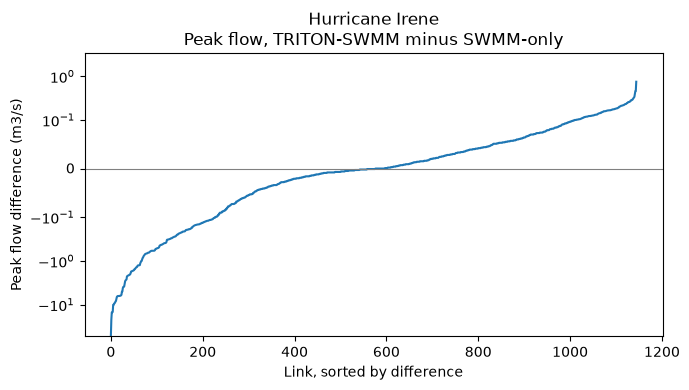

In [3]:
flow_coupled = tree["tritonswmm/swmm_link"].to_dataset()["max_flow"].isel(event_iloc=0)
flow_swmm = tree["swmm_only/swmm_link"].to_dataset()["max_flow"].isel(event_iloc=0)
flow_coupled, flow_swmm = xr.align(flow_coupled, flow_swmm, join="inner")
flow_difference = flow_coupled - flow_swmm
flow_difference = flow_difference.sortby(flow_difference)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(flow_difference.sizes["link_id"]), flow_difference.values)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_yscale("symlog", linthresh=0.1)
ax.set_xlabel("Link, sorted by difference")
ax.set_ylabel("Peak flow difference (m3/s)")
ax.set_title("Hurricane Irene\nPeak flow, TRITON-SWMM minus SWMM-only")
fig.tight_layout()
plt.show()

## Peak flood depth difference

The second plot subtracts the peak depth of each cell in the TRITON-only simulation from the peak depth of the same cell in the TRITON-SWMM simulation. Both simulations share the grid, so the subtraction needs no alignment. The variable `max_flood_depth` holds the depth of water above the ground and reads 0 in dry cells. Blue marks cells where the coupled simulation records the lower peak depth. The color range is symmetric about zero, and the arrow at the bottom of the color bar marks values below the range.

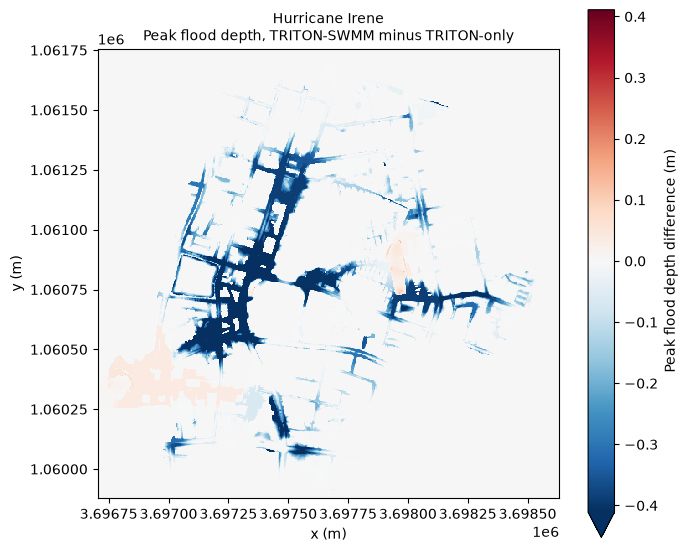

In [4]:
depth_coupled = tree["tritonswmm/triton"].to_dataset()["max_flood_depth"].isel(event_iloc=0)
depth_triton = tree["triton_only/triton"].to_dataset()["max_flood_depth"].isel(event_iloc=0)
depth_difference = depth_coupled - depth_triton

fig, ax = plt.subplots(figsize=(7, 6))
depth_difference.plot(
    ax=ax,
    cmap="RdBu_r",
    center=0,
    robust=True,
    cbar_kwargs={"label": "Peak flood depth difference (m)"},
)
ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("Hurricane Irene\nPeak flood depth, TRITON-SWMM minus TRITON-only", fontsize=10)
fig.tight_layout()
plt.show()

## Next steps

- [Simulating an event ensemble](../norfolk-observed-events/) covers observed storms on the Norfolk case study.
- [Config filling](../../how-to/config-filling/) covers the fields of the system and analysis configs.